**Experiment: Feature Engineering Using Machine Learning**


1. Aim - To implement feature engineering techniques to transform raw data into informative features using the House Prices dataset.

**2. Objectives** 1. To load and explore the House Prices dataset. 2. To identify and handle missing values. 3. To convert categorical data into numerical form using encoding techniques. 4. To create new meaningful features from existing columns. 5. To detect and handle outliers using the Interquartile Range (IQR) method. 6. To apply feature scaling using Min-Max Scaling and Standardization. 7. To select useful features using correlation analysis. 8. To prepare the transformed dataset for machine learning.

**3. Problem Statement**- Raw datasets may contain missing values, categorical data, outliers, and features that are not directly suitable for machine learning algorithms. Feature engineering is performed to clean and transform the dataset into a useful format. In this experiment, the Student Performance dataset is processed using missing-value handling, categorical encoding, feature creation, outlier detection, feature scaling, and feature selection.


**4: Dataset Description**
Property	Details
Dataset name	Student Performance (student-mat.csv)
Domain	Education
Records	395 students
Original columns	33
Target variable	G3
Problem type	Supervised learning; regression if predicting the final grade

**5. Software and Libraries Required**
- Python — programming language
- Google Colab — environment for running Python code
- Pandas — loading, exploring, and processing data
- NumPy — numerical operations
- Matplotlib — creating graphs
- Seaborn — creating statistical visualizations
- Scikit-learn — scaling features and preparing data for machine learning

**Importing Required Libraries and Loading the Dataset**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/student-mat.csv', sep=';')

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


**7: Algorithm**
Write this algorithm in your practical journal:
1. Start.
2. Import the required Python libraries.
3. Load the Student Performance dataset.
4. Explore the dataset and identify missing values.
5. Handle missing values using suitable methods.
6. Encode categorical features into numerical form.
7. Create new features from existing columns.
8. Detect outliers using boxplots and the IQR method.
9. Handle outliers using capping.
10. Apply Min-Max Scaling and Standardization.
11. Perform correlation analysis and select relevant features.
12. Display the transformed dataset.
13. Save the results and write the conclusion.
14. Stop.

In [3]:
print("First 5 rows")
display(df.head())

print("Last 5 rows")
display(df.tail())

print("Dataset shape:", df.shape)

print("Column names")
print(df.columns.tolist())

print("Data types")
print(df.dtypes)

print("Dataset information")
df.info()

print("Statistical summary")
display(df.describe())

print("Missing values in each column")
print(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

First 5 rows


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Last 5 rows


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10
394,MS,M,19,U,LE3,T,1,1,other,at_home,...,3,2,3,3,3,5,5,8,9,9


Dataset shape: (395, 33)
Column names
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
Data types
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences      

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


Missing values in each column
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Total missing values: 0
Duplicate rows: 0


In [4]:
df_clean = df.copy()

for col in df_clean.columns:
    if df_clean[col].isnull().any():
        if df_clean[col].dtype == 'object':
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
        else:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Missing values before handling:", df.isnull().sum().sum())
print("Missing values after handling:", df_clean.isnull().sum().sum())

Missing values before handling: 0
Missing values after handling: 0


In [5]:
cat_cols = df_clean.select_dtypes(include='object').columns

print("Categorical columns:")
print(list(cat_cols))

df_encoded = pd.get_dummies(
    df_clean,
    columns=cat_cols,
    dtype=int
)

print("Original shape:", df_clean.shape)
print("Encoded shape:", df_encoded.shape)

display(df_encoded.head())

Categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Original shape: (395, 33)
Encoded shape: (395, 59)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,0,1,0,1,1,0,1,0
1,17,1,1,1,2,0,5,3,3,1,...,1,0,1,0,0,1,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,0,1,0,1,0,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,0,1,0,1,0,1,0,1,0,1
4,16,3,3,1,2,0,4,3,2,1,...,1,0,0,1,0,1,1,0,1,0


In [6]:
df_features = df_encoded.copy()

df_features['AveragePreviousGrade'] = (
    df_features['G1'] + df_features['G2']
) / 2

df_features['GradeImprovement'] = (
    df_features['G2'] - df_features['G1']
)

print("New features created")

display(
    df_features[
        ['G1', 'G2', 'AveragePreviousGrade', 'GradeImprovement']
    ].head()
)

New features created


,G1,G2,AveragePreviousGrade,GradeImprovement
0,5,6,5.5,1
1,5,5,5.0,0
2,7,8,7.5,1
3,15,14,14.5,-1
4,6,10,8.0,4


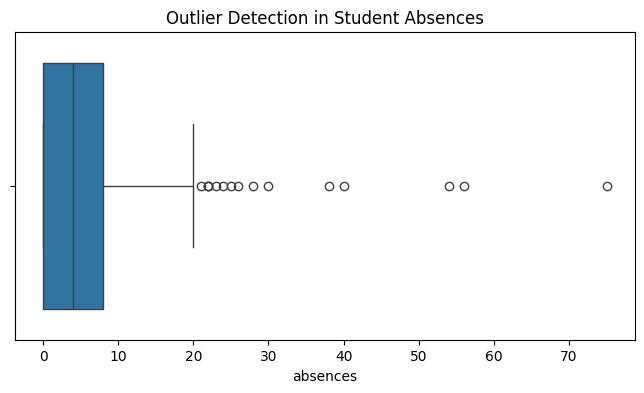

Q1: 0.0
Q3: 8.0
IQR: 8.0
Lower bound: -12.0
Upper bound: 20.0
Number of outliers: 15


In [7]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df_clean, x='absences')

plt.title("Outlier Detection in Student Absences")
plt.show()

Q1 = df_clean['absences'].quantile(0.25)
Q3 = df_clean['absences'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean['absences'] < lower_bound) |
    (df_clean['absences'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

In [8]:
df_capped = df_clean.copy()

df_capped['absences'] = df_capped['absences'].clip(
    lower=lower_bound,
    upper=upper_bound
)

print("Original maximum absences:", df_clean['absences'].max())
print("Maximum after capping:", df_capped['absences'].max())

display(df_capped[['absences']].head())

Original maximum absences: 75
Maximum after capping: 20


,absences
0,6
1,4
2,10
3,2
4,4


In [9]:
from sklearn.preprocessing import MinMaxScaler

scale_cols = ['age', 'absences', 'G1', 'G2', 'G3']

scaler = MinMaxScaler()

df_minmax = df_capped.copy()

df_minmax[scale_cols] = scaler.fit_transform(
    df_minmax[scale_cols]
)

print("Data after Min-Max Scaling:")
display(df_minmax[scale_cols].head())

Data after Min-Max Scaling:


,age,absences,G1,G2,G3
0,0.428571,0.3,0.1250,0.315789,0.30
1,0.285714,0.2,0.1250,0.263158,0.30
2,0.000000,0.5,0.2500,0.421053,0.50
3,0.000000,0.1,0.7500,0.736842,0.75
4,0.142857,0.2,0.1875,0.526316,0.50


In [10]:
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()

df_standard = df_capped.copy()

df_standard[scale_cols] = standard_scaler.fit_transform(
    df_standard[scale_cols]
)

print("Data after Standardization:")
display(df_standard[scale_cols].head())

Data after Standardization:


,age,absences,G1,G2,G3
0,1.023046,0.142892,-1.782467,-1.254791,-0.964934
1,0.238380,-0.208773,-1.782467,-1.520979,-0.964934
2,-1.330954,0.846221,-1.179147,-0.722415,-0.090739
3,-1.330954,-0.560438,1.234133,0.874715,1.002004
4,-0.546287,-0.208773,-1.480807,-0.190038,-0.090739


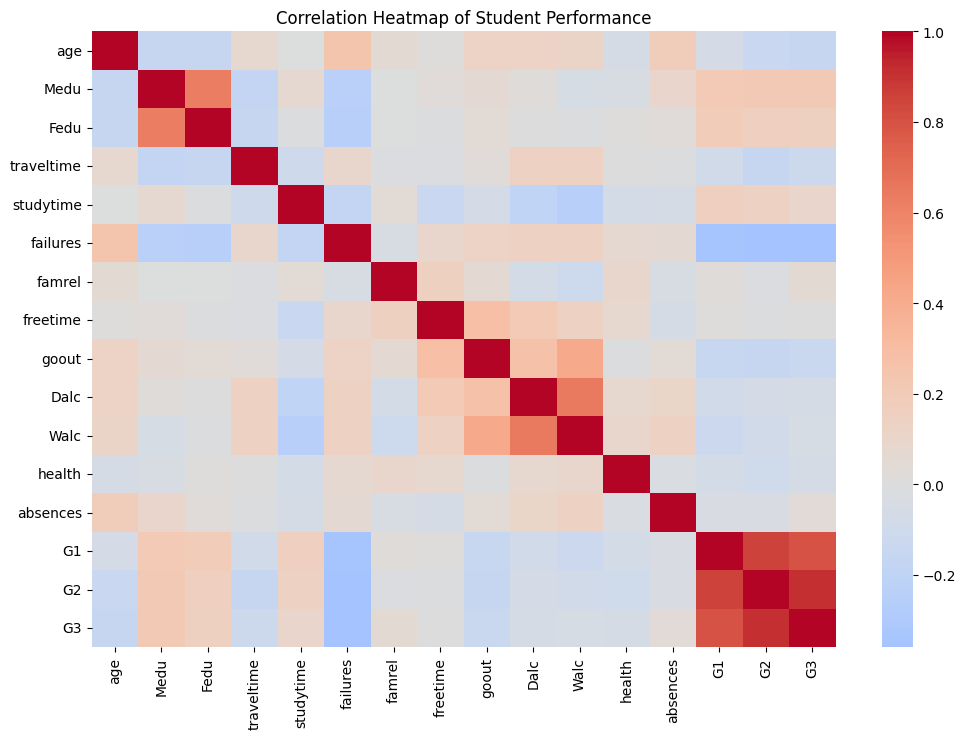

In [11]:
correlation = df_clean.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0
)

plt.title("Correlation Heatmap of Student Performance")
plt.show()

In [12]:
target_corr = correlation['G3'].drop('G3')

top_features = (
    target_corr.abs()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 features correlated with G3:")
print(top_features)

Top 10 features correlated with G3:
G2            0.904868
G1            0.801468
failures      0.360415
Medu          0.217147
age           0.161579
Fedu          0.152457
goout         0.132791
traveltime    0.117142
studytime     0.097820
health        0.061335
Name: G3, dtype: float64


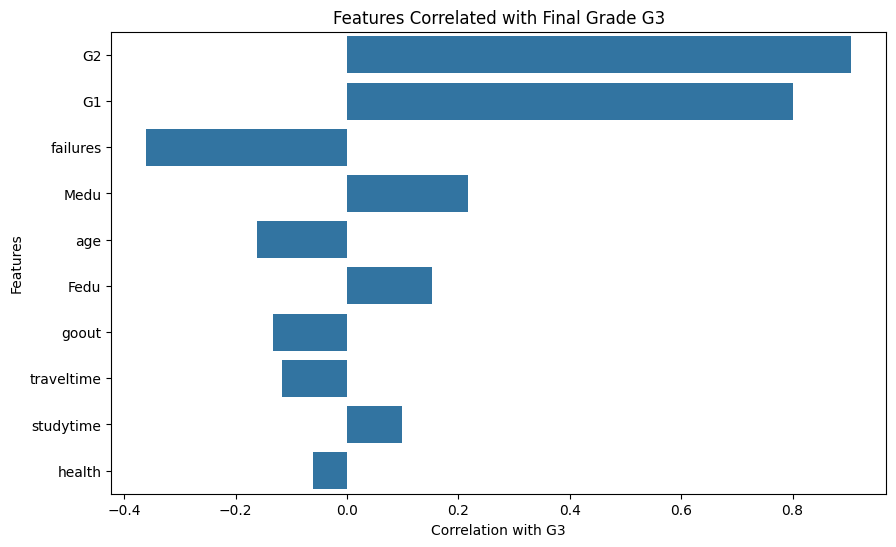

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=target_corr.loc[top_features.index].values,
    y=top_features.index
)

plt.title("Features Correlated with Final Grade G3")
plt.xlabel("Correlation with G3")
plt.ylabel("Features")

plt.show()

In [14]:
selected_features = [
    'studytime',
    'failures',
    'absences',
    'G1',
    'G2'
]

X = df_clean[selected_features]
y = df_clean['G3']

print("Selected features:")
display(X.head())

print("Target variable:")
display(y.head())

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Selected features:


,studytime,failures,absences,G1,G2
0,2,0,6,5,6
1,2,0,4,5,5
2,2,3,10,7,8
3,3,0,2,15,14
4,2,0,4,6,10


Target variable:


,G3
0,6
1,6
2,10
3,15
4,10


Feature matrix shape: (395, 5)
Target shape: (395,)


Display and save the transformed dataset

In [15]:
print("Original dataset shape:", df.shape)
print("Encoded dataset shape:", df_encoded.shape)
print("Feature-created dataset shape:", df_features.shape)
print("Min-Max scaled dataset shape:", df_minmax.shape)
print("Standardized dataset shape:", df_standard.shape)

print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

display(df_minmax.head())

Original dataset shape: (395, 33)
Encoded dataset shape: (395, 59)
Feature-created dataset shape: (395, 61)
Min-Max scaled dataset shape: (395, 33)
Standardized dataset shape: (395, 33)
Remaining missing values: 0
Duplicate rows: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,0.428571,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,0.3,0.1250,0.315789,0.30
1,GP,F,0.285714,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,0.2,0.1250,0.263158,0.30
2,GP,F,0.000000,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,0.5,0.2500,0.421053,0.50
3,GP,F,0.000000,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0.1,0.7500,0.736842,0.75
4,GP,F,0.142857,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0.2,0.1875,0.526316,0.50


Save the transformed data

In [16]:
df_minmax.to_csv(
    '/content/student_performance_transformed.csv',
    index=False
)

print("Transformed dataset saved successfully.")

Transformed dataset saved successfully.


In [17]:
from google.colab import files

files.download('/content/student_performance_transformed.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Result**

Feature engineering techniques were implemented on the Student Performance dataset. The experiment included dataset exploration, missing-value handling, categorical encoding, feature creation, outlier detection using the IQR method, outlier capping, Min-Max Scaling, Standardization, correlation analysis, and feature selection.

**Conclusion** - feature engineering was successfully performed on the Student Performance dataset using Python in Google Colab. The dataset was explored and transformed using suitable preprocessing techniques. Categorical data was encoded, new features were created, outliers were identified and capped, numerical features were scaled, and relevant features were selected using correlation analysis